In [28]:
from typing import TypedDict
from langgraph.graph import END, StateGraph

In [29]:
class State(TypedDict):
    messages: list
    next_step: str

In [30]:
def user_input_node(state: State):
    return {"messages": state["messages"]}

In [31]:
def model_node(state: State):
  # Let's say the model decides to use a tool *only on the first pass*,
  # or we can check how many messages we have.
  if len(state["messages"]) < 2:
    return {"next_step": "tools"}
  else:
    return {"next_step": "done"}  # Exit condition!

In [32]:
def tools_node(state: State):

    return {"messages": state["messages"] + ["Tool execution result"]}

In [33]:
workflow = StateGraph(State)

# 1. Add all three nodes
workflow.add_node("user_input", user_input_node)
workflow.add_node("model", model_node)
workflow.add_node("tools", tools_node)

workflow.set_entry_point("user_input")

# Linear edge from start to model
workflow.add_edge("user_input", "model")

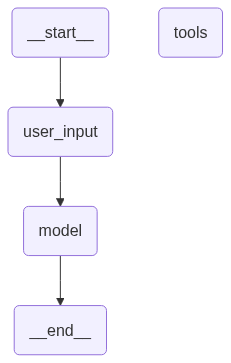

In [34]:
app = workflow.compile()
app

In [35]:
# A simple routing function that reads the state
def should_continue(state: State):
  if state["next_step"] == "tools":
    return "continue_to_tools"
  return "stop"


# Add the conditional edge coming out of "model"
workflow.add_conditional_edges(
    "model",  # Source node
    should_continue,  # The routing function that returns a string key
    {
        "continue_to_tools": "tools",  # If router returns "continue_to_tools", go to "tools" node
        "stop": END,  # If router returns "stop", go to END
    },
)

# After the tools run, where do they go? Usually back to the model (creating a loop!)
workflow.add_edge("tools", "model")

app = workflow.compile()

Adding an edge to a graph that has already been compiled. This will not be reflected in the compiled graph.
Adding an edge to a graph that has already been compiled. This will not be reflected in the compiled graph.


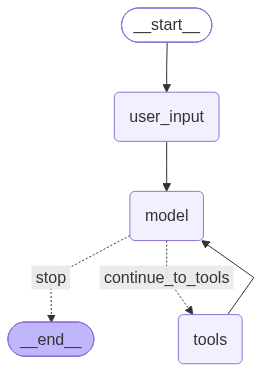

In [36]:
app

In [20]:
result = app.invoke({"messages": ["Hello, write a poem"]})
result

{'messages': ['Hello, write a poem', 'Tool execution result'],
 'next_step': 'done'}

In [27]:
for event in app.stream({"messages": ["Hello, write a poem"]}, stream_mode="updates"):
  print(event)
  print("-" * 40)

{'user_input': {'messages': ['Hello, write a poem']}}
----------------------------------------
{'model': {'next_step': 'tools'}}
----------------------------------------
{'tools': {'messages': ['Hello, write a poem', 'Tool execution result']}}
----------------------------------------
{'model': {'next_step': 'done'}}
----------------------------------------


#Nodes: Executable functions that take the current state, perform a task (like calling an LLM, running a tool, or parsing text), and return a state update.

#Edges (and Conditional Edges): The pathways and routers that inspect the state and dynamically decide which node goes next (e.g., “If tool_called is True, go to the tool execution node; otherwise, end.”).

#Shared State: Often implemented using a schema like a TypedDict or Pydantic model acting as the centralized memory store accessible and updatable by every node.